# Mental Model: Churn Prediction with Logistic Regression

Everything in this notebook is built from **two kinds of objects**, and each follows the same two-phase pattern: **learn from training data, then apply to any data.**

| Object | Role | Learn step | Apply step | What it learns |
|---|---|---|---|---|
| `DictVectorizer` (`dv`) | Converts rows into a numeric matrix | `.fit()` | `.transform()` | Which columns exist (e.g. `contract=month-to-month`, `contract=one_year`) and their order |
| `LogisticRegression` (`model`) | Predicts churn probability | `.fit()` | `.predict_proba()` | One weight per column, plus a bias |

---

## Data flow

The pipeline has **three stages**, run in order. Training data is used to *learn*; validation data is only used to *apply* what was learned.

```
STAGE 1: Learn the encoding
───────────────────────────
df_train ──► .to_dict() ──► train_dict
                               │
                       dv.fit(train_dict)         learns the column layout
                               │
                       dv.transform(train_dict)
                               │
                               ▼
                            X_train


STAGE 2: Learn the weights
──────────────────────────
X_train + y_train ──► model.fit(X_train, y_train)     learns one weight per column


STAGE 3: Predict on new data
────────────────────────────
df_val ──► .to_dict() ──► val_dict
                             │
                     dv.transform(val_dict)          same dv, NO re-fit
                             │
                             ▼
                          X_val
                             │
                     model.predict_proba(X_val)      uses the learned weights
                             │
                             ▼
                        [:, 1] ──► y_pred            P(churn) per customer
```

### Tiny example

Training data has 2 customers:

```python
train_dict = [{'contract': 'month-to-month', 'tenure': 5},
              {'contract': 'two_year',       'tenure': 40}]
y_train    = [1, 0]   # 1 = churned
```

| Step | Result |
|---|---|
| `dv.fit(train_dict)` | learns columns `['contract=month-to-month', 'contract=two_year', 'tenure']` |
| `dv.transform(train_dict)` | `[[1, 0, 5], [0, 1, 40]]` |
| `model.fit(X_train, y_train)` | learns 3 weights + a bias |
| `dv.transform(val_dict)` on `[{'contract': 'two_year', 'tenure': 10}]` | `[[0, 1, 10]]` |
| `model.predict_proba(X_val)` | `[[0.8, 0.2]]` = `[P(stay), P(churn)]` |
| `[:, 1]` | `[0.2]` |

**Key rule:** validation data never calls `.fit()`. It must use the layout `dv` learned from training, so its columns line up with the model's weights.
## Walking through the code

**1. Data prep.** Clean the CSV and turn `churn` into 0/1. Split into train, validation and test sets. `y_train` and `y_val` (the answers) are pulled out and deleted from the feature frames, so the features can't leak the answer.

**2. Feature lists.** `categorical` and `numerical` are just lists of column names. They define which columns become features.

**3. Vectorizing.**
- `to_dict(orient='records')` turns each row into a dict like `{'contract': 'month-to-month', 'tenure': 5, ...}`.
- `dv.fit(train_dict)` scans these dicts and records the layout. String values get one-hot columns; numbers pass through unchanged.
- `dv.transform(train_dict)` produces the actual matrix `X_train` using that layout.

**4. Training.** `model.fit(X_train, y_train)` learns the weights. This is the only step where the model "learns".

**5. Predicting.** `model.predict_proba(X_val)` returns two columns per row: `[P(no churn), P(churn)]`. `[:, 1]` keeps only the churn probability, giving a 1-D array `y_pred`.

**6. The "small" model.** This is the *exact same pipeline again*, with a separate `dv_small` and `model_small` and only 3 features (`contract`, `tenure`, `totalcharges`). It exists so you can compare a simple model against the full one.

---

## Rules to keep in mind

1. **Fit on train only, then transform everything else.** Validation data never calls `.fit()`. It must be encoded with the layout learned from training, otherwise the columns won't match what the model's weights expect.
2. **Each vectorizer belongs to its model.** `dv` goes with `model`, and `dv_small` goes with `model_small`. Their column layouts differ (the full one has dozens of columns, the small one only a handful), so mixing them would break or give nonsense.
3. **`y_train` is shared** by both models, because both train on the same rows. Only the features differ.
4. **Vocabulary:**
   - `fit` = learn
   - `transform` = apply a learned encoding
   - `predict_proba` = apply learned weights
   - The printout `LogisticRegression(random_state=1, solver='liblinear')` is just the model object echoing its settings, not a result.

---

## Sanity checks you can run

```python
dv.get_feature_names_out()          # the learned column layout
X_train.shape, X_small_train.shape  # compare feature counts
model.coef_, model.intercept_       # the learned weights
```

Pair the names with the weights to see which feature each weight belongs to:

```python
pd.Series(model.coef_[0], index=dv.get_feature_names_out()).sort_values()
```

---

## What's next

Nothing here *evaluates* anything yet. `y_pred` and `y_pred_small` are just predictions. The next step is comparing them against `y_val` with a metric like accuracy or AUC.

## Week 4 CodeLab below: 

In [1]:
%pip install -q kagglehub pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Downloaded to:", path)

Downloaded to: /home/codespace/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1


In [3]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [5]:
import pandas as pd

df = pd.read_csv(f"{path}/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors="coerce")
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isnull().sum()

df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
# identify columns that are strings
df.dtypes == 'str'
string_columns = list(df.dtypes[df.dtypes == 'str'].index)
for col in string_columns: 
    df[col] = df[col].str.lower().str.replace(" ","_")

df.head()

df.Churn = (df.Churn == 'yes').astype(int)

In [9]:
# Test Train Split using scikit-learn

df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_train_full,test_size=0.33,random_state=1)

df_train_full.shape, df_train.shape, df_val.shape, df_test.shape

df_train_full.shape, df_train.shape, df_val.shape, df_test.shape


#Why do we not isolate the feature matrix for the testing dataset? 
y_train = df_train['Churn']
y_val = df_val['Churn']
#y_test = df_test['Churn']

In [10]:
del df_train['Churn']
del df_val['Churn']

In [11]:
df_train

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
4204,4395-pzmsn,male,1,no,no,5,yes,no,fiber_optic,no,yes,no,no,no,yes,month-to-month,yes,electronic_check,85.55,408.50
7034,0639-tsiqw,female,0,no,no,67,yes,yes,fiber_optic,yes,yes,yes,no,yes,no,month-to-month,yes,credit_card_(automatic),102.95,6886.25
5146,3797-fkogq,male,0,no,yes,11,yes,yes,fiber_optic,no,no,no,no,no,yes,month-to-month,no,electronic_check,86.20,893.20
5184,7570-welny,female,0,yes,no,68,yes,yes,fiber_optic,yes,yes,no,no,no,no,two_year,yes,bank_transfer_(automatic),84.70,5711.05
1310,6393-wryze,female,0,yes,no,34,yes,yes,fiber_optic,no,no,no,no,yes,yes,month-to-month,yes,electronic_check,97.65,3207.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3774,1309-xgfsn,male,1,yes,yes,52,yes,yes,dsl,no,yes,yes,no,yes,yes,one_year,yes,electronic_check,80.85,4079.55
6108,4819-hjpiw,male,0,no,no,18,no,no_phone_service,dsl,no,no,no,no,no,no,month-to-month,no,mailed_check,25.15,476.80
1530,3703-vavcl,male,0,yes,yes,2,yes,no,fiber_optic,no,no,yes,yes,no,yes,month-to-month,no,credit_card_(automatic),90.00,190.05
3701,3812-lrzir,female,0,yes,yes,27,yes,yes,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,electronic_check,24.50,761.95


In [12]:
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents',
               'phoneservice', 'multiplelines', 'internetservice',
               'onlinesecurity', 'onlinebackup', 'deviceprotection',
               'techsupport', 'streamingtv', 'streamingmovies',
               'contract', 'paperlessbilling', 'paymentmethod']
numerical = ['tenure', 'monthlycharges', 'totalcharges']


In [13]:
train_dict = df_train.rename(columns=str.lower)[categorical + numerical].to_dict(orient='records')

#one-hot encoding
dv = DictVectorizer(sparse=False) # learn the column layout
# for the categorical variables, using the transformed dict, we will create binary flags
X_train = dv.fit_transform(train_dict) # build the training matrix using that layout 



In [14]:
model = LogisticRegression(solver='liblinear', random_state=1)
# P(churn) = sigmoid( bias + w1·feature1 + w2·feature2 + ... + wn·featuren )
model.fit(X_train,y_train) 
model.coef_        # the weights, one per column of X_train
model.intercept_   # the bias

array([-0.10802122])

In [15]:
# After training the model (learning the weights), we create predictions on the validation dataset

val_dict = df_val.rename(columns=str.lower)[categorical + numerical].to_dict(orient='records')

X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:,1]

y_pred



array([0.00857286, 0.20971288, 0.21635546, ..., 0.64335704, 0.18944084,
       0.12738071], shape=(1860,))

In [16]:

# normalize the column names before selecting them
df_train.columns = df_train.columns.str.lower().str.replace(" ", "_")

small_subset = ['contract', 'tenure', 'totalcharges']
df_train[small_subset]

train_dict_small = df_train[small_subset].to_dict(orient='records')
dv_small = DictVectorizer(sparse=False)
dv_small.fit(train_dict_small)

X_small_train = dv_small.transform(train_dict_small)
model_small = LogisticRegression(solver='liblinear', random_state=1)
model_small.fit(X_small_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_

In [17]:
df_val = df_val.rename(columns=lambda x: x.lower().replace(" ", "_"))
val_dict_small = df_val[small_subset].to_dict(orient='records')
X_small_val = dv_small.transform(val_dict_small)

y_pred_small = model_small.predict_proba(X_small_val)[:, 1]

In [18]:
y_pred = model.predict_proba(X_val)[:, 1]
churn = y_pred >= 0.5
(churn == y_val).mean()

np.float64(0.8048387096774193)

In [19]:
len(y_val)

1860

In [20]:
(churn == y_val).sum()

np.int64(1497)

In [21]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val,y_pred >= 0.5)

0.8048387096774193

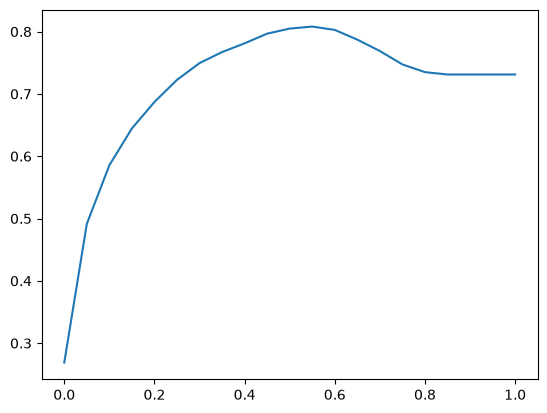

In [22]:
thresholds = np.linspace(0,1,21)
thresholds

scores = []

for t in thresholds: 
    score = accuracy_score(y_val,y_pred >= t)
    scores.append(score)

scores
plt.plot(thresholds,scores)


# Evaluating a Churn Classifier: Accuracy, Precision, and Recall

## 1. Setup

In the customer churn problem, logistic regression outputs a **probability of churn** for each customer, $P(\text{churn} \mid x)$. To get a class label, we apply a **decision threshold** (default $0.5$):

$$
\hat{y} =
\begin{cases}
1 \ (\text{churn}) & \text{if } P(\text{churn}) \ge \text{threshold} \\
0 \ (\text{stay})  & \text{otherwise}
\end{cases}
$$

By convention, **churn = positive class (1)** and **stay = negative class (0)**.

---

## 2. The Confusion Matrix: TP, FP, TN, FN

Every prediction falls into one of four buckets, comparing the model's prediction to what actually happened:

|                        | **Predicted: Churn (1)** | **Predicted: Stay (0)** |
|------------------------|:------------------------:|:-----------------------:|
| **Actual: Churn (1)**  | **TP** (True Positive)   | **FN** (False Negative) |
| **Actual: Stay (0)**   | **FP** (False Positive)  | **TN** (True Negative)  |

| Term | Meaning | Churn example |
|------|---------|---------------|
| **TP** | Predicted churn, and the customer did churn | We flagged them, and they really were leaving. A correct catch. |
| **FP** | Predicted churn, but the customer stayed | We flagged them, but they were fine. A false alarm (e.g., a wasted discount offer). |
| **TN** | Predicted stay, and the customer stayed | We left them alone, and they stayed. A correct "all clear". |
| **FN** | Predicted stay, but the customer churned | We missed them, and they left. A missed churner (lost revenue). |

> **Memory trick:** The second letter (P/N) is what the *model predicted*. The first letter (T/F) is whether that prediction was *correct*.

---

## 3. The Metrics

### Accuracy
*Of all predictions, what fraction was correct?*

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

### Precision
*Of the customers we **flagged as churners**, what fraction actually churned?*

$$
\text{Precision} = \frac{TP}{TP + FP}
$$

- Answers: **"When the model cries churn, how often is it right?"**
- Low precision means many false alarms (wasted retention spend).

### Recall (Sensitivity, True Positive Rate)
*Of the customers who **actually churned**, what fraction did we catch?*

$$
\text{Recall} = \frac{TP}{TP + FN}
$$

- Answers: **"How many of the real churners did we find?"**
- Low recall means many missed churners (lost customers).

### F1 Score (optional)
The harmonic mean of precision and recall, useful as a single balanced number:

$$
F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$

---

## 4. Worked Example

Suppose we score 1,000 customers, of whom 100 actually churned (10% churn rate):

|                        | Predicted Churn | Predicted Stay |
|------------------------|:---------------:|:--------------:|
| **Actual Churn (100)** | TP = 60         | FN = 40        |
| **Actual Stay (900)**  | FP = 50         | TN = 850       |

$$
\text{Accuracy} = \frac{60 + 850}{1000} = 0.91
$$

$$
\text{Precision} = \frac{60}{60 + 50} \approx 0.545
$$

$$
\text{Recall} = \frac{60}{60 + 40} = 0.60
$$

**Takeaway:** Accuracy looks great at 91%, yet nearly half of our churn flags are false alarms and 40% of churners slip through.

---

## 5. Why Accuracy Alone Is Misleading (Class Imbalance)

Churn datasets are usually **imbalanced**, with far more customers staying than leaving. A useless model that predicts *"nobody churns"* for everyone would score:

$$
\text{Accuracy} = \frac{0 + 900}{1000} = 90\%, \qquad \text{Recall} = \frac{0}{0 + 100} = 0\%
$$

It looks accurate and catches **zero** churners. This is why we look at **precision and recall** on the positive (churn) class.

---

## 6. The Precision–Recall Trade-off and the Threshold

The threshold on the logistic regression output controls the trade-off:

| Threshold | Model behavior | Precision | Recall |
|-----------|----------------|:---------:|:------:|
| **Lower** (e.g., 0.3) | Flags more customers as churners | ↓ | ↑ |
| **Higher** (e.g., 0.7) | Flags only the most confident cases | ↑ | ↓ |

**Which should you prioritize?** It depends on the business cost:

- **Retention offer is cheap, losing a customer is costly** → favor **recall** (catch as many churners as possible, tolerate false alarms).
- **Retention offer is expensive** (big discount, account manager time) → favor **precision** (only spend on likely churners).

---

## 7. Quick Reference

| Metric | Formula | Question it answers | Penalizes |
|--------|---------|---------------------|-----------|
| Accuracy | $\frac{TP+TN}{\text{Total}}$ | How often is the model right overall? | All errors equally |
| Precision | $\frac{TP}{TP+FP}$ | When it predicts churn, is it right? | False positives |
| Recall | $\frac{TP}{TP+FN}$ | Does it find the actual churners? | False negatives |
| F1 | $2\cdot\frac{P \cdot R}{P + R}$ | Is there a balance of both? | Imbalance between P and R |

In [23]:
from collections import Counter
Counter(y_pred >= 1.0)


Counter({np.False_: 1860})

In [31]:
y_val

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [39]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

confusion_matrix

array([[1217,  143],
       [ 220,  280]])

In [41]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.08],
       [0.12, 0.15]])

## Precision & Recall
1. precision is the fraction of positive predictions that are correct -- true positive / total positive predictions (churn)
2. recall is the fraction of correctly identified positive examples -- true positive / people who actually ended up being positive (churning)

In [43]:
precision = tp / (tp + fp)
precision

np.float64(0.6619385342789598)

In [45]:
recall = tp / (tp + fn)
recall

np.float64(0.56)